# Dimensionality and Visual Analysis

This notebook explores the cleaned multi-omics datasets before model training. The goal is to verify that selected ovarian-cancer-relevant gene panels are present across the available omics layers and to visualize how these genes are positioned within the broader mRNA-seq and copy-number alteration feature spaces.

The raw data has already been cleaned, processed for missing values, and structured into analysis-ready files. This notebook therefore starts from the cleaned `.pkl` datasets rather than repeating the raw cleaning process.

## 1. Import Libraries

This section imports the libraries used for data loading, tabular gene-panel checks, dimensionality reduction, and visualization. PCA and t-SNE are used for exploratory dimensionality analysis, while PrettyTable is used to summarize gene availability across omics layers.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler 
from sklearn.manifold import TSNE
from prettytable import PrettyTable


## 2. Survival-Relevant 101-Gene Panel

This section defines a 101-gene list collected from ovarian-cancer survival-related literature. The list is used as the main biological reference panel for later availability checks and dimensionality visualizations. The goal is to see whether this curated survival-related panel is represented in the cleaned mRNA-seq, CNA, and methylation datasets.

In [2]:
gene_list_P1 = [
    "CDH1", "STK16", "MAL", "GJB1", "TESK1", "PTH2R", "DNAJC9", "SRI", "WWP1", "AKT1S1",
    "MYOD1", "NF1", "CPNE1", "BNIP3L", "NUCB2", "AADAC", "MITF", "CEACAM5", "GMNN", "ATP5A1",
    "C19orf12", "BRCA2", "GMPR", "SMARCA4", "PCDH9", "MAK", "PCK2", "GFRA1", "BAALC", "RNASEL",
    "B4GALT5", "MYC", "LPAR3", "DUSP4", "CDKN3", "E2F6", "FAM58A", "PARP4", "KRT6", "FOXJ1",
    "HSP90AA1", "USP8", "HIF1A", "SMO", "CTLA4", "CCNE1", "ASRGL1", "FGFR1", "IL22", "PPP2R4",
    "ZFHX4", "SPTLC2", "PD.1", "FOXP3", "RB1", "CXCL10", "PAX2", "OPA1", "EZR", "OASL",
    "RARRES1", "ANXA4", "HBB", "SERPINE1", "MINPP1", "APPL2", "MRPS27", "MDM2", "CDK6", "CRABP2",
    "SHPRH", "WDR91", "NTRK2", "GUSB", "OR1G1", "TAP1", "ESR2", "IGHM", "CX3CR1", "MRE11A",
    "VCAN", "GTF2H5", "MEST", "IGF2", "KDM5D", "TCF7L1", "VSIG4", "NF2", "FOXRED2", "MAP2K4",
    "ADH1B", "TBX2", "NUAK2", "ESD", "FGF1", "ZNHIT2", "PGRA", "KLHL7", "SOX17", "TSHR", "CXCL9"
]
#101 gene list from https://www.annalsofoncology.org/article/S0923-7534(20)39841-0/fulltext that are essential for survival.
print(len(gene_list_P1))

101


## 3. Load Cleaned Multi-Omics Data and Check Gene Availability

The cleaned mRNA-seq, log2 copy-number alteration, and methylation datasets are loaded from the final processed data folder. The first row of the mRNA-seq and CNA files contains gene names, while the methylation file maps CpG features to gene names in the second row. Multi-gene methylation annotations are split so that genes separated by semicolons can still be detected.

The table below checks whether each gene from the 101-gene survival panel is available in each omics layer. This matters because a gene must be present in an omics dataset before it can contribute to downstream feature selection, dimensionality analysis, or model interpretation.

In [3]:


# File paths
mrna_path = "../Datafiles Final/Datafiles Cleaned/mrnaseqv2.pkl"
cna_path =  "../Datafiles Final/Datafiles Cleaned/log2cna.pkl"
methylation_path =  "../Datafiles Final/Datafiles Cleaned/methylation.pkl"

# Load the data
mrna_df = pd.read_pickle(mrna_path)  # mRNA dataset
cna_df = pd.read_pickle(cna_path)  # CNA dataset
methylation_df = pd.read_pickle(methylation_path)  # Methylation dataset

# Extract genes from first row for mRNA and CNA
mrna_genes = set(mrna_df.iloc[0])  
cna_genes = set(cna_df.iloc[0])    

# Extract genes from second row for Methylation, splitting multi-gene cells
methylation_raw_genes = methylation_df.iloc[1]  
methylation_genes = set()
for entry in methylation_raw_genes:
    if isinstance(entry, str):  # Ensure it's a valid string before splitting
        methylation_genes.update(entry.split(";"))

# Create a PrettyTable
table = PrettyTable()
table.field_names = ["Gene", "In mRNAseq", "In log2CNA", "In Methylation"]

# Populate the table
for gene in gene_list_P1:
    table.add_row([
        gene,
        "Yes" if gene in mrna_genes else "No",
        "Yes" if gene in cna_genes else "No",
        "Yes" if gene in methylation_genes else "No"
    ])

# Print the table
print(table)


+----------+------------+------------+----------------+
|   Gene   | In mRNAseq | In log2CNA | In Methylation |
+----------+------------+------------+----------------+
|   CDH1   |    Yes     |    Yes     |      Yes       |
|  STK16   |    Yes     |    Yes     |      Yes       |
|   MAL    |    Yes     |    Yes     |      Yes       |
|   GJB1   |    Yes     |    Yes     |      Yes       |
|  TESK1   |    Yes     |    Yes     |      Yes       |
|  PTH2R   |    Yes     |    Yes     |      Yes       |
|  DNAJC9  |    Yes     |    Yes     |      Yes       |
|   SRI    |    Yes     |    Yes     |      Yes       |
|   WWP1   |    Yes     |    Yes     |      Yes       |
|  AKT1S1  |    Yes     |    Yes     |      Yes       |
|  MYOD1   |     No     |    Yes     |      Yes       |
|   NF1    |    Yes     |    Yes     |      Yes       |
|  CPNE1   |    Yes     |    Yes     |      Yes       |
|  BNIP3L  |    Yes     |    Yes     |      Yes       |
|  NUCB2   |    Yes     |    Yes     |      Yes 

## 4. Additional Ovarian Cancer Gene Panels

Two additional gene panels are defined for comparison. These panels are used alongside the 101-gene survival list to highlight ovarian-cancer-relevant genes in the visualizations. Comparing multiple panels helps check whether different literature-derived gene groups are represented across the same omics datasets.

In [4]:
panel_1 = [
    "LTBP4", "PTGS1", "SLC25A25", "LAMC2", "LRG1", "DHCR24", "LDLR", "SPP1", "IL1B", "IL1RN",
    "KRT23", "ALDH3B2", "SUSD2", "DEFB1", "HLA-DQA2", "CYP4B1", "PIGR", "SPARC", "SERPINF1",
    "DCN", "SFRP4", "CRISPLD2", "TIMP3", "CNN1", "MYH11", "MFAP4", "ENG", "EFEMP1", "RGS16",
    "FEN1", "NUSAP1", "UBE2C", "ZWINT", "PRC1", "ASF1B", "MCM4", "GINS2", "CENPM", "MCM2",
    "TK1", "MCM6", "SMC4", "CENPU", "MAD2L1", "TEKT1", "FAM92B", "SNTN", "LRRC46", "EFCAB1",
    "CDHR3", "C6orf118", "CCDC78"
]
panel_2 = [
    "LTBP4", "SLC25A25", "LAMC2", "DHCR24", "PLK3", "LRG1", "LDLR", "SPP1", "IL1B", "IL1RN",
    "KRT23", "ALDH3B2", "SUSD2", "DEFB1", "HLA-DQA2", "CYP4B1", "PIGR", "SPARC", "SERPINF1",
    "DCN", "SFRP4", "CRISPLD2", "TIMP3", "CNN1", "MYH11", "MFAP4", "ENG", "EFEMP1", "RGS16",
    "FEN1", "NUSAP1", "UBE2C", "ZWINT", "PRC1", "ASF1B", "MCM4", "GINS2", "CENPM", "MCM2",
    "TK1", "MCM6", "SMC4", "CENPU", "MAD2L1", "TEKT1", "TUBA4B", "C20orf85", "CAPSL",
    "LRRC46", "EFCAB1", "C6orf118", "CCDC78"
]


## 5. Panel 1 Availability Across Omics Layers

This table checks whether each Panel 1 gene is available in the cleaned mRNA-seq, CNA, and methylation datasets. The purpose is to confirm that the genes used for later overlays are actually present in the data, rather than assuming that every literature gene is available in each modality.

In [5]:
# Create a PrettyTable
table1 = PrettyTable()
table1.field_names = ["Gene", "In mRNAseq", "In log2CNA", "In Methylation"]

# Populate the table
for gene in panel_1:
    table1.add_row([
        gene,
        "Yes" if gene in mrna_genes else "No",
        "Yes" if gene in cna_genes else "No",
        "Yes" if gene in methylation_genes else "No"
    ])

# Print the table
print(table1)



+----------+------------+------------+----------------+
|   Gene   | In mRNAseq | In log2CNA | In Methylation |
+----------+------------+------------+----------------+
|  LTBP4   |    Yes     |    Yes     |      Yes       |
|  PTGS1   |    Yes     |    Yes     |      Yes       |
| SLC25A25 |    Yes     |    Yes     |      Yes       |
|  LAMC2   |    Yes     |    Yes     |      Yes       |
|   LRG1   |    Yes     |    Yes     |      Yes       |
|  DHCR24  |    Yes     |    Yes     |      Yes       |
|   LDLR   |    Yes     |    Yes     |      Yes       |
|   SPP1   |    Yes     |    Yes     |       No       |
|   IL1B   |    Yes     |    Yes     |      Yes       |
|  IL1RN   |    Yes     |    Yes     |      Yes       |
|  KRT23   |    Yes     |    Yes     |      Yes       |
| ALDH3B2  |    Yes     |    Yes     |       No       |
|  SUSD2   |    Yes     |    Yes     |      Yes       |
|  DEFB1   |    Yes     |    Yes     |      Yes       |
| HLA-DQA2 |    Yes     |    Yes     |       No 

## 6. Panel 2 Availability Across Omics Layers

This table repeats the availability check for Panel 2. It helps compare coverage across the same three omics layers and confirms which genes can be used in later exploratory visualizations.

In [6]:
# Create a PrettyTable
table1 = PrettyTable()
table1.field_names = ["Gene", "In mRNAseq", "In log2CNA", "In Methylation"]

# Populate the table
for gene in panel_2:
    table1.add_row([
        gene,
        "Yes" if gene in mrna_genes else "No",
        "Yes" if gene in cna_genes else "No",
        "Yes" if gene in methylation_genes else "No"
    ])

# Print the table
print(table1)



+----------+------------+------------+----------------+
|   Gene   | In mRNAseq | In log2CNA | In Methylation |
+----------+------------+------------+----------------+
|  LTBP4   |    Yes     |    Yes     |      Yes       |
| SLC25A25 |    Yes     |    Yes     |      Yes       |
|  LAMC2   |    Yes     |    Yes     |      Yes       |
|  DHCR24  |    Yes     |    Yes     |      Yes       |
|   PLK3   |    Yes     |    Yes     |      Yes       |
|   LRG1   |    Yes     |    Yes     |      Yes       |
|   LDLR   |    Yes     |    Yes     |      Yes       |
|   SPP1   |    Yes     |    Yes     |       No       |
|   IL1B   |    Yes     |    Yes     |      Yes       |
|  IL1RN   |    Yes     |    Yes     |      Yes       |
|  KRT23   |    Yes     |    Yes     |      Yes       |
| ALDH3B2  |    Yes     |    Yes     |       No       |
|  SUSD2   |    Yes     |    Yes     |      Yes       |
|  DEFB1   |    Yes     |    Yes     |      Yes       |
| HLA-DQA2 |    Yes     |    Yes     |       No 

## 7. Prepare Gene-Level Matrices for Visualization

This section restructures the cleaned mRNA-seq and CNA data so that genes become rows and patient samples become columns. This format is needed for PCA and t-SNE because each gene is treated as an observation described by its values across patients.

The preparation step removes metadata rows, transposes the data, and uses gene names as the index. This does not train a model; it only prepares the feature matrices for exploratory visualization.

In [7]:
 # Ensure StandardScaler is imported



# Load the data (assumes data are stored as DataFrames with samples as rows and genes as columns)
mrna_df = pd.read_pickle(mrna_path)
cna_df = pd.read_pickle(cna_path)

# Define your gene panels
gene_list_P1 = [
    "CDH1", "STK16", "MAL", "GJB1", "TESK1", "PTH2R", "DNAJC9", "SRI", "WWP1", "AKT1S1",
    "MYOD1", "NF1", "CPNE1", "BNIP3L", "NUCB2", "AADAC", "MITF", "CEACAM5", "GMNN", "ATP5A1",
    "C19orf12", "BRCA2", "GMPR", "SMARCA4", "PCDH9", "MAK", "PCK2", "GFRA1", "BAALC", "RNASEL",
    "B4GALT5", "MYC", "LPAR3", "DUSP4", "CDKN3", "E2F6", "FAM58A", "PARP4", "KRT6", "FOXJ1",
    "HSP90AA1", "USP8", "HIF1A", "SMO", "CTLA4", "CCNE1", "ASRGL1", "FGFR1", "IL22", "PPP2R4",
    "ZFHX4", "SPTLC2", "PD.1", "FOXP3", "RB1", "CXCL10", "PAX2", "OPA1", "EZR", "OASL",
    "RARRES1", "ANXA4", "HBB", "SERPINE1", "MINPP1", "APPL2", "MRPS27", "MDM2", "CDK6", "CRABP2",
    "SHPRH", "WDR91", "NTRK2", "GUSB", "OR1G1", "TAP1", "ESR2", "IGHM", "CX3CR1", "MRE11A",
    "VCAN", "GTF2H5", "MEST", "IGF2", "KDM5D", "TCF7L1", "VSIG4", "NF2", "FOXRED2", "MAP2K4",
    "ADH1B", "TBX2", "NUAK2", "ESD", "FGF1", "ZNHIT2", "PGRA", "KLHL7", "SOX17", "TSHR", "CXCL9"
]

panel_1 = [
    "LTBP4", "PTGS1", "SLC25A25", "LAMC2", "LRG1", "DHCR24", "LDLR", "SPP1", "IL1B", "IL1RN",
    "KRT23", "ALDH3B2", "SUSD2", "DEFB1", "HLA-DQA2", "CYP4B1", "PIGR", "SPARC", "SERPINF1",
    "DCN", "SFRP4", "CRISPLD2", "TIMP3", "CNN1", "MYH11", "MFAP4", "ENG", "EFEMP1", "RGS16",
    "FEN1", "NUSAP1", "UBE2C", "ZWINT", "PRC1", "ASF1B", "MCM4", "GINS2", "CENPM", "MCM2",
    "TK1", "MCM6", "SMC4", "CENPU", "MAD2L1", "TEKT1", "FAM92B", "SNTN", "LRRC46", "EFCAB1",
    "CDHR3", "C6orf118", "CCDC78"
]

panel_2 = [
    "LTBP4", "SLC25A25", "LAMC2", "DHCR24", "PLK3", "LRG1", "LDLR", "SPP1", "IL1B", "IL1RN",
    "KRT23", "ALDH3B2", "SUSD2", "DEFB1", "HLA-DQA2", "CYP4B1", "PIGR", "SPARC", "SERPINF1",
    "DCN", "SFRP4", "CRISPLD2", "TIMP3", "CNN1", "MYH11", "MFAP4", "ENG", "EFEMP1", "RGS16",
    "FEN1", "NUSAP1", "UBE2C", "ZWINT", "PRC1", "ASF1B", "MCM4", "GINS2", "CENPM", "MCM2",
    "TK1", "MCM6", "SMC4", "CENPU", "MAD2L1", "TEKT1", "TUBA4B", "C20orf85", "CAPSL",
    "LRRC46", "EFCAB1", "C6orf118", "CCDC78"
]

def prepare_data_for_pca(df):
    """
    Prepares the data for PCA by:
    - Removing the second row (metadata).
    - Removing the patient ID as index.
    - Transposing the data so that genes become rows and samples become columns.
    - Setting the first column after transposing as the new index (gene names).
    - Converting all values to numeric.
    """
    # Remove only the second row
    df_numeric = df.drop(index=df.index[1])

    # Reset index to remove patient ID as index and keep it as a normal column
    df_numeric = df_numeric.reset_index(drop=True)

    # Transpose the DataFrame: genes should be rows, samples should be columns
    df_transposed = df_numeric.T

    # Set the first column after transposing as the new index (gene names)
    df_transposed = df_transposed.set_index(df_transposed.columns[0])


    return df_transposed


# Prepare the mRNA and CNA data
mrna_numeric = prepare_data_for_pca(mrna_df)
cna_numeric = prepare_data_for_pca(cna_df)

## 8. 2D PCA Visualization With Gene Panel Overlays

Principal Component Analysis is used to reduce the high-dimensional gene-by-patient matrix into two principal components. Each point represents one gene, positioned according to its variation pattern across patients.

All genes are shown in gray, while genes from the 101-gene survival list and the two additional panels are overlaid in color. This helps visually inspect whether ovarian-cancer-relevant genes occupy identifiable regions within the broader gene-expression or CNA feature space.

                 PC1       PC2
0                             
UBE2Q2P3   -4.466561 -0.028858
UBE2Q2P2   -4.462231 -0.027266
HMGB1P1    -3.447287  0.006427
TIMM23      1.135949 -0.195223
LOC155060  -3.176395  0.017754
...              ...       ...
ZYG11A     -4.308258 -0.015489
ZYG11B     -1.136516 -0.099166
ZYX        19.689123  1.835669
ZZEF1      -0.990070  0.318628
ZZZ3       -0.545358 -0.131850

[19076 rows x 2 columns]


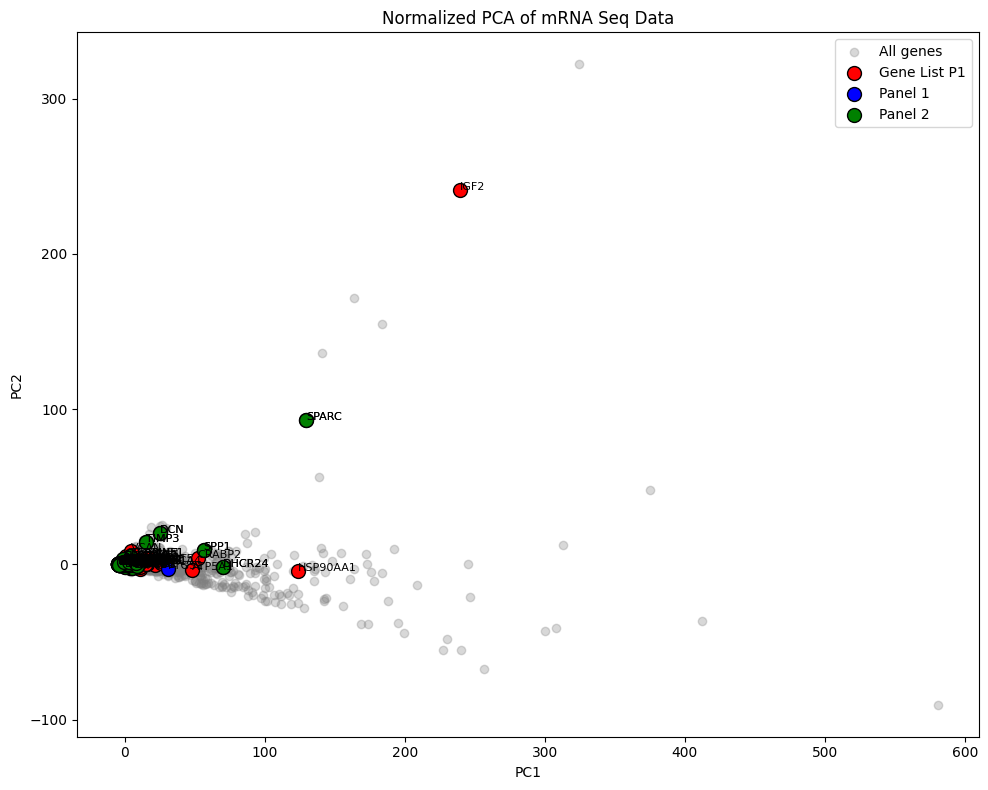

                     PC1       PC2
0                                 
ACAP3          -1.860019 -2.153711
ACTRT2         -1.860019 -2.153711
AGRN           -1.860019 -2.153711
ANKRD65        -1.860019 -2.153711
ATAD3A         -1.860019 -2.153711
...                  ...       ...
hsa-mir-513c    3.228073  2.734848
hsa-mir-513b    3.228073  2.734848
hsa-mir-513a-1  3.228073  2.734848
hsa-mir-513a-2  3.228073  2.734848
hsa-mir-224     4.633374  3.570238

[25128 rows x 2 columns]


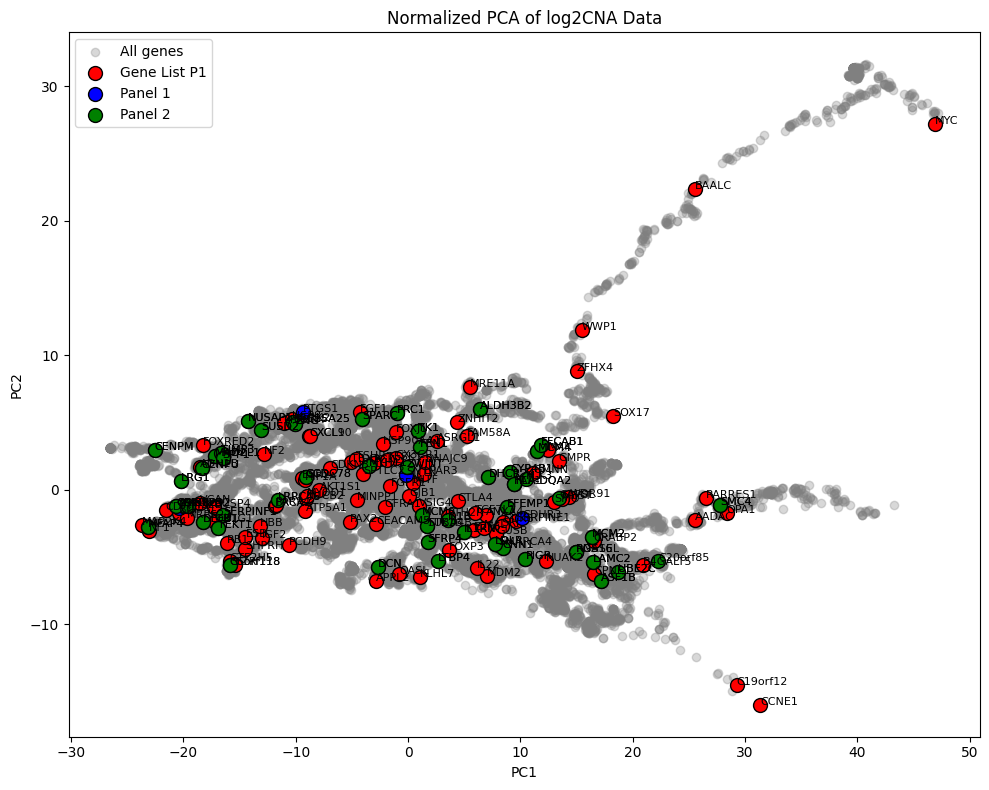

In [8]:
def plot_normalized_pca(data_genes, title):
    """
    Transposes the data so that each row represents a gene (across patients),
    normalizes the data, performs PCA, and plots the first two principal components
    with gene panel overlays.
    """

    # Drop genes with any missing values (if any)
    data_genes = data_genes.dropna(axis=0)
    # Normalize the data so each gene has zero mean and unit variance
    scaler = StandardScaler()
    data_scaled = scaler.fit_transform(data_genes)

    # Perform PCA to extract the first two principal components
    pca = PCA(n_components=2)
    pca_scores = pca.fit_transform(data_scaled)

    # Create a DataFrame for PCA scores with gene names as index
    pca_df = pd.DataFrame(pca_scores, index=data_genes.index, columns=["PC1", "PC2"])
    
    # Plot all genes with a light marker
    plt.figure(figsize=(10, 8))
    plt.scatter(pca_df["PC1"], pca_df["PC2"], color='gray', alpha=0.3, label="All genes")
    
    # Define panels with specific colors and labels
    panels = [
        (gene_list_P1, 'red', 'Gene List P1'),
        (panel_1, 'blue', 'Panel 1'),
        (panel_2, 'green', 'Panel 2')
    ]
    print(pca_df)
    
    # Overlay gene panel genes
    for panel, color, label in panels:
        # Only select genes present in the PCA results
        common_genes = list(set(panel) & set(pca_df.index))
        if common_genes:
            subset = pca_df.loc[common_genes]
            plt.scatter(subset["PC1"], subset["PC2"], color=color, edgecolor='k',
                        s=100, label=label)
            # Add gene labels for clarity
            for gene in common_genes:
                plt.text(subset.loc[gene, "PC1"], subset.loc[gene, "PC2"], gene, fontsize=8)
    
    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.legend()
    plt.tight_layout()
    plt.show()

    return pca_df

# Plot normalized PCA for mRNA seq data with gene panels overlaid
mrna_pca_df = plot_normalized_pca(mrna_numeric, "Normalized PCA of mRNA Seq Data")

# Plot normalized PCA for log2CNA data with gene panels overlaid
cna_pca_df = plot_normalized_pca(cna_numeric, "Normalized PCA of log2CNA Data")


## 9. t-SNE Visualization With Gene Panel Overlays

This section applies t-SNE to the normalized gene-level matrices. Unlike PCA, which captures linear variation, t-SNE is useful for showing local neighborhood structure in high-dimensional data.

The purpose of this visualization is to see whether the selected ovarian-cancer gene panels appear across the embedded gene clusters. When genes from the 101-gene survival list are present within or near different t-SNE clusters, those clusters become more interpretable because they are connected back to biologically relevant ovarian-cancer features. This does not mean that every cluster is fully explained by the 101-gene list, but it shows that the curated survival-related genes help represent and contextualize parts of the overall gene-feature structure.

               tSNE1      tSNE2
0                              
UBE2Q2P3  -54.491688 -29.286024
UBE2Q2P2  -54.441887 -29.253477
HMGB1P1    -7.085746 -19.223581
TIMM23     55.405457  15.654844
LOC155060 -15.418018 -15.316291


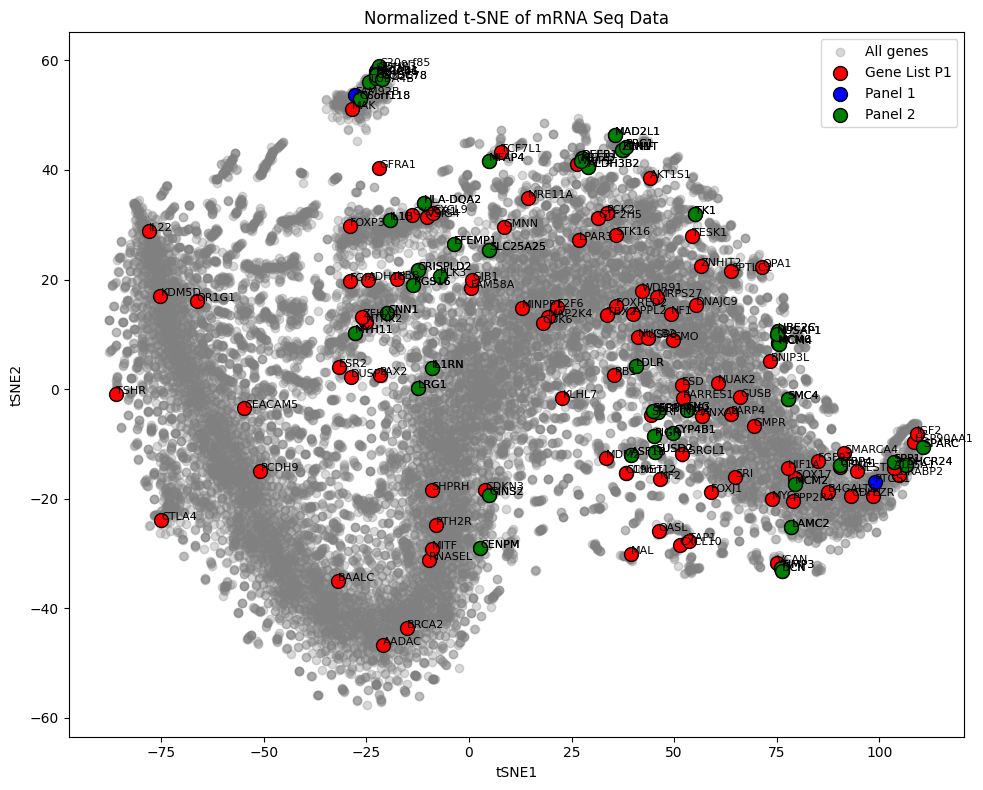

             tSNE1       tSNE2
0                             
ACAP3   -30.016687 -102.134911
ACTRT2  -30.535271 -102.155632
AGRN    -29.464285 -101.669563
ANKRD65 -30.535271 -102.155632
ATAD3A  -30.535271 -102.155632


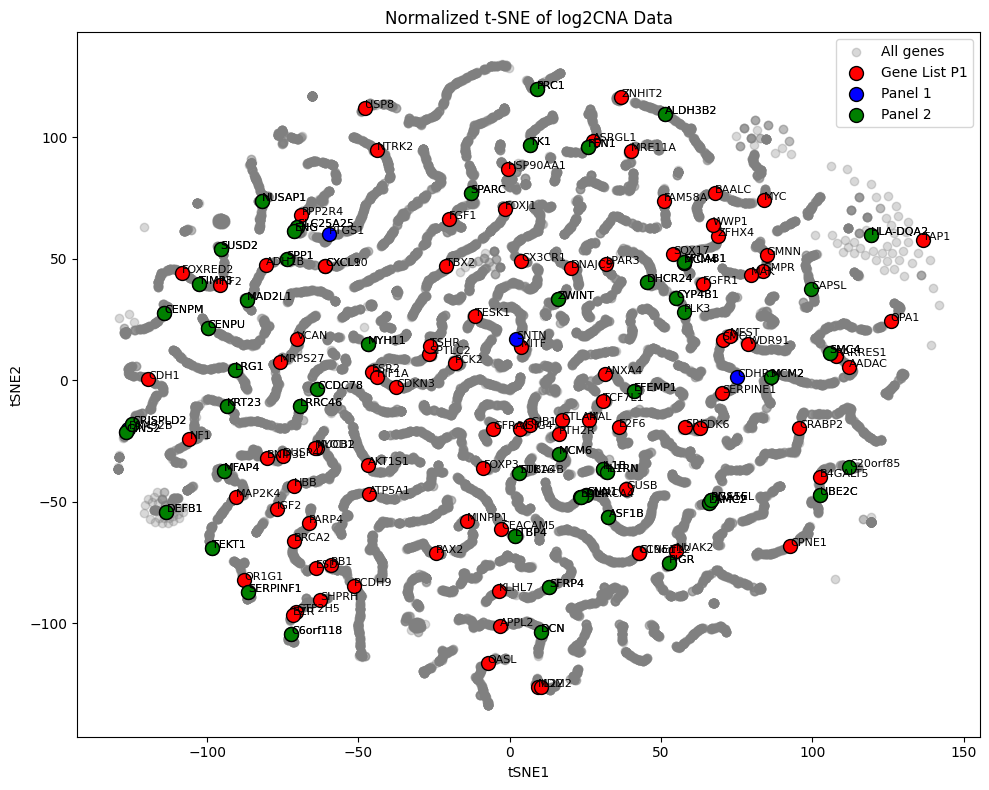

In [9]:




# Load the data (assumes data are stored as DataFrames with samples as rows and genes as columns)
mrna_df = pd.read_pickle(mrna_path)
cna_df = pd.read_pickle(cna_path)

# Define your gene panels
gene_list_P1 = [
    "CDH1", "STK16", "MAL", "GJB1", "TESK1", "PTH2R", "DNAJC9", "SRI", "WWP1", "AKT1S1",
    "MYOD1", "NF1", "CPNE1", "BNIP3L", "NUCB2", "AADAC", "MITF", "CEACAM5", "GMNN", "ATP5A1",
    "C19orf12", "BRCA2", "GMPR", "SMARCA4", "PCDH9", "MAK", "PCK2", "GFRA1", "BAALC", "RNASEL",
    "B4GALT5", "MYC", "LPAR3", "DUSP4", "CDKN3", "E2F6", "FAM58A", "PARP4", "KRT6", "FOXJ1",
    "HSP90AA1", "USP8", "HIF1A", "SMO", "CTLA4", "CCNE1", "ASRGL1", "FGFR1", "IL22", "PPP2R4",
    "ZFHX4", "SPTLC2", "PD.1", "FOXP3", "RB1", "CXCL10", "PAX2", "OPA1", "EZR", "OASL",
    "RARRES1", "ANXA4", "HBB", "SERPINE1", "MINPP1", "APPL2", "MRPS27", "MDM2", "CDK6", "CRABP2",
    "SHPRH", "WDR91", "NTRK2", "GUSB", "OR1G1", "TAP1", "ESR2", "IGHM", "CX3CR1", "MRE11A",
    "VCAN", "GTF2H5", "MEST", "IGF2", "KDM5D", "TCF7L1", "VSIG4", "NF2", "FOXRED2", "MAP2K4",
    "ADH1B", "TBX2", "NUAK2", "ESD", "FGF1", "ZNHIT2", "PGRA", "KLHL7", "SOX17", "TSHR", "CXCL9"
]

panel_1 = [
    "LTBP4", "PTGS1", "SLC25A25", "LAMC2", "LRG1", "DHCR24", "LDLR", "SPP1", "IL1B", "IL1RN",
    "KRT23", "ALDH3B2", "SUSD2", "DEFB1", "HLA-DQA2", "CYP4B1", "PIGR", "SPARC", "SERPINF1",
    "DCN", "SFRP4", "CRISPLD2", "TIMP3", "CNN1", "MYH11", "MFAP4", "ENG", "EFEMP1", "RGS16",
    "FEN1", "NUSAP1", "UBE2C", "ZWINT", "PRC1", "ASF1B", "MCM4", "GINS2", "CENPM", "MCM2",
    "TK1", "MCM6", "SMC4", "CENPU", "MAD2L1", "TEKT1", "FAM92B", "SNTN", "LRRC46", "EFCAB1",
    "CDHR3", "C6orf118", "CCDC78"
]

panel_2 = [
    "LTBP4", "SLC25A25", "LAMC2", "DHCR24", "PLK3", "LRG1", "LDLR", "SPP1", "IL1B", "IL1RN",
    "KRT23", "ALDH3B2", "SUSD2", "DEFB1", "HLA-DQA2", "CYP4B1", "PIGR", "SPARC", "SERPINF1",
    "DCN", "SFRP4", "CRISPLD2", "TIMP3", "CNN1", "MYH11", "MFAP4", "ENG", "EFEMP1", "RGS16",
    "FEN1", "NUSAP1", "UBE2C", "ZWINT", "PRC1", "ASF1B", "MCM4", "GINS2", "CENPM", "MCM2",
    "TK1", "MCM6", "SMC4", "CENPU", "MAD2L1", "TEKT1", "TUBA4B", "C20orf85", "CAPSL",
    "LRRC46", "EFCAB1", "C6orf118", "CCDC78"
]

def prepare_data_for_tsne(df):
    """
    Prepares the data for t-SNE by:
    - Removing the second row (metadata).
    - Removing the patient ID as index.
    - Transposing the data so that genes become rows and samples become columns.
    - Setting the first column (after transposing) as the new index (gene names).
    - Converting all values to numeric.
    """
    # Remove only the second row
    df_numeric = df.drop(index=df.index[1])
    
    # Reset index to remove patient ID as index
    df_numeric = df_numeric.reset_index(drop=True)
    
    # Transpose the DataFrame so genes become rows and samples become columns
    df_transposed = df_numeric.T
    
    # Set the first column (after transposing) as the new index (gene names)
    df_transposed = df_transposed.set_index(df_transposed.columns[0])
    
    # Convert all values to numeric (non-numeric values become NaN)
    df_transposed = df_transposed.apply(pd.to_numeric, errors='coerce')
    
    return df_transposed

# Prepare the mRNA and CNA data
mrna_numeric = prepare_data_for_tsne(mrna_df)
cna_numeric = prepare_data_for_tsne(cna_df)

def plot_normalized_tsne(data_genes, title):
    """
    Transposes the data so that each row represents a gene (across patients),
    normalizes the data, performs t-SNE, and plots the first two t-SNE components
    with gene panel overlays.
    """
    # Drop genes with any missing values (if any)
    data_genes = data_genes.dropna(axis=0)
    
    # Normalize the data so each gene has zero mean and unit variance
    scaler = StandardScaler()
    data_scaled = scaler.fit_transform(data_genes)
    
    # Perform t-SNE to extract two components
    tsne = TSNE(n_components=2, random_state=42)
    tsne_scores = tsne.fit_transform(data_scaled)
    
    # Create a DataFrame for t-SNE scores with gene names as index
    tsne_df = pd.DataFrame(tsne_scores, index=data_genes.index, columns=["tSNE1", "tSNE2"])
    
    # Plot all genes with a light marker
    plt.figure(figsize=(10, 8))
    plt.scatter(tsne_df["tSNE1"], tsne_df["tSNE2"], color='gray', alpha=0.3, label="All genes")
    
    # Define panels with specific colors and labels
    panels = [
        (gene_list_P1, 'red', 'Gene List P1'),
        (panel_1, 'blue', 'Panel 1'),
        (panel_2, 'green', 'Panel 2')
    ]
    
    print(tsne_df.head())
    
    # Overlay gene panel genes
    for panel, color, label in panels:
        # Only select genes present in the t-SNE results
        common_genes = list(set(panel) & set(tsne_df.index))
        if common_genes:
            subset = tsne_df.loc[common_genes]
            plt.scatter(subset["tSNE1"], subset["tSNE2"], color=color, edgecolor='k',
                        s=100, label=label)
            # Add gene labels for clarity
            for gene in common_genes:
                plt.text(subset.loc[gene, "tSNE1"], subset.loc[gene, "tSNE2"], gene, fontsize=8)
    
    plt.title(title)
    plt.xlabel("tSNE1")
    plt.ylabel("tSNE2")
    plt.legend()
    plt.tight_layout()
    plt.show()
    
    return tsne_df

# Plot normalized t-SNE for mRNA seq data with gene panels overlaid
mrna_tsne_df = plot_normalized_tsne(mrna_numeric, "Normalized t-SNE of mRNA Seq Data")

# Plot normalized t-SNE for log2CNA data with gene panels overlaid
cna_tsne_df = plot_normalized_tsne(cna_numeric, "Normalized t-SNE of log2CNA Data")


## 10. Interactive 3D PCA Visualization

The 3D PCA plot extends the previous PCA analysis by using the first three principal components. This provides an interactive view of the same gene-level structure, making it easier to inspect the relative position of panel genes compared with the full feature space.

This visualization is exploratory. It is mainly used to check whether biologically relevant genes are distributed across the high-dimensional structure rather than being absent or isolated from the main gene patterns.

In [10]:


def plot_normalized_pca_3d_interactive(data_genes, title):
    """
    Prepares the data, computes PCA with 3 components, and creates an interactive 3D plot using Plotly.
    
    Parameters:
    - data_genes: DataFrame with genes as rows (after preprocessing)
    - title: Title of the plot
    
    Returns:
    - pca_df: DataFrame with PCA scores (PC1, PC2, PC3)
    """
    # Drop genes with any missing values
    data_genes = data_genes.dropna(axis=0)
    
    # Normalize the data (zero mean, unit variance)
    scaler = StandardScaler()
    data_scaled = scaler.fit_transform(data_genes)
    
    # Perform PCA for three components
    pca = PCA(n_components=3)
    pca_scores = pca.fit_transform(data_scaled)
    
    # Create a DataFrame for PCA scores with gene names as index
    pca_df = pd.DataFrame(pca_scores, index=data_genes.index, columns=["PC1", "PC2", "PC3"])
    
    # Create a trace for all genes in gray
    trace_all = go.Scatter3d(
        x = pca_df["PC1"],
        y = pca_df["PC2"],
        z = pca_df["PC3"],
        mode = 'markers',
        marker = dict(size=4, color='gray'),
        name = 'All genes',
        text = pca_df.index
    )
    
    # Define panels with their colors and labels
    panels = [
        (gene_list_P1, 'red', 'Gene List P1'),
        (panel_1, 'blue', 'Panel 1'),
        (panel_2, 'green', 'Panel 2')
    ]
    
    traces = [trace_all]
    
    # Add a trace for each gene panel
    for panel, color, label in panels:
        common_genes = list(set(panel) & set(pca_df.index))
        if common_genes:
            subset = pca_df.loc[common_genes]
            trace = go.Scatter3d(
                x = subset["PC1"],
                y = subset["PC2"],
                z = subset["PC3"],
                mode = 'markers+text',
                marker = dict(size=8, color=color, line=dict(color='black', width=1)),
                text = subset.index,
                textposition = "top center",
                name = label
            )
            traces.append(trace)
    
    # Define layout for the 3D plot
    layout = go.Layout(
        title=title,
        width=1000,  # Increased plot width
        height=1000,  # Increased plot height
        scene=dict(
            xaxis_title="PC1",
            yaxis_title="PC2",
            zaxis_title="PC3"
        )
    )
    
    # Create and display the interactive figure
    fig = go.Figure(data=traces, layout=layout)
    fig.show()
    
    return pca_df

# Example usage:
# Assuming mrna_numeric and cna_numeric have been prepared using your preprocessing function.
mrna_pca_df = plot_normalized_pca_3d_interactive(mrna_numeric, "Interactive 3D PCA of mRNA Seq Data")
cna_pca_df = plot_normalized_pca_3d_interactive(cna_numeric, "Interactive 3D PCA of log2CNA Data")


## 11. Gene-Level Matrix Inspection

This display cell is a quick inspection of the prepared mRNA-seq matrix after restructuring. Rows represent genes and columns represent patient samples. It is useful for confirming that the transformation worked before running variability and visualization steps.

In [11]:
mrna_numeric

,1,2,3,4,5,6,7,8,9,10,...,291,292,293,294,295,296,297,298,299,300
0,,,,,,,,,,,,,,,,,,,,,
UBE2Q2P3,22.028266,17.671802,21.976720,14.940150,10.382058,2.733694,19.315232,20.896304,5.421443,1.190590,...,4.923308,20.466544,41.372838,20.519959,7.149914,21.566391,32.307387,26.118873,34.475700,126.819903
UBE2Q2P2,25.716221,20.473921,29.909980,7.827355,4.877826,6.227180,15.088948,27.821347,10.171431,24.953771,...,2.486953,29.214074,43.867435,48.929509,6.756215,8.630438,26.618719,15.716029,28.912917,59.400754
HMGB1P1,321.241331,128.865135,424.021806,400.227877,891.927121,380.425710,507.815414,856.606003,371.023437,218.291376,...,335.265779,131.919622,305.443765,68.665161,225.455747,92.597754,203.931820,400.614342,309.174887,431.623999
TIMM23,1952.678661,901.425735,1366.864827,1775.819439,1886.589299,1371.327702,1525.885484,721.340307,1070.351388,1392.102710,...,1596.217812,1128.424392,1026.626852,1172.472325,1142.036809,1291.281828,588.503145,1304.656225,1345.236051,1460.986221
LOC155060,222.150613,244.412320,377.449014,339.460985,128.196713,396.171828,89.765797,586.616738,314.560329,111.235044,...,264.341700,687.011933,528.956140,570.717733,228.074966,439.904885,510.841037,387.776781,412.614342,540.597847
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZYG11A,6.824650,4.775693,66.800880,15.651470,8.691137,24.236724,3.320645,10.812258,10.887130,5.662495,...,10.768112,37.768199,11.964642,23.172043,84.289826,137.984157,33.829916,141.004912,7.760542,79.382924
ZYG11B,483.942790,518.654716,791.336454,701.294430,891.615830,935.538347,1081.073819,410.169901,597.638326,456.027533,...,714.170417,890.967623,913.879586,934.138220,860.248654,670.929813,1793.289275,1000.073852,1321.299392,1068.161532
ZYX,9692.870954,3284.754545,3747.937644,3647.207428,4404.299470,3583.030316,9961.232422,2941.540137,7331.180099,3409.126710,...,11158.354211,4559.453197,5640.258550,9311.826985,2797.563049,4145.227437,6202.950375,6698.448007,4961.305257,3907.580348


## 12. Static Visualization of Gene-Level Variability

This section ranks genes by variability using mean absolute deviation and then plots normalized values across samples. Genes with stronger variation across patients are more visually prominent and may be more informative for downstream modeling.

The static plot gives a broad view of how gene values vary after sorting by variability.

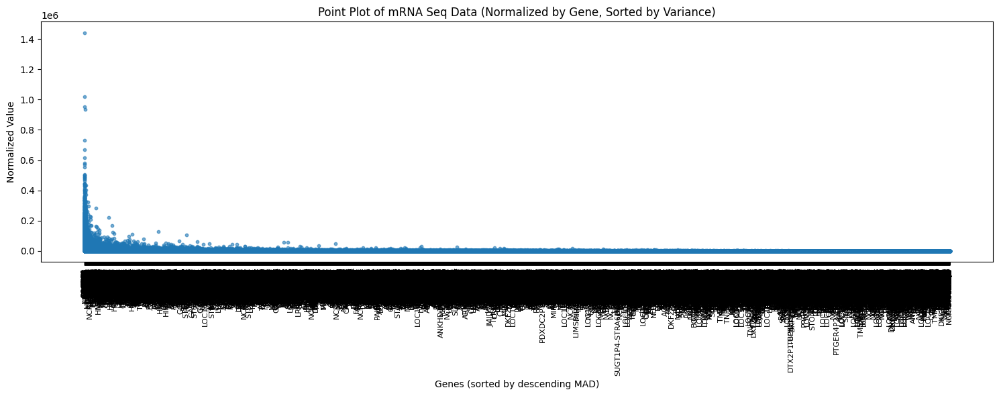

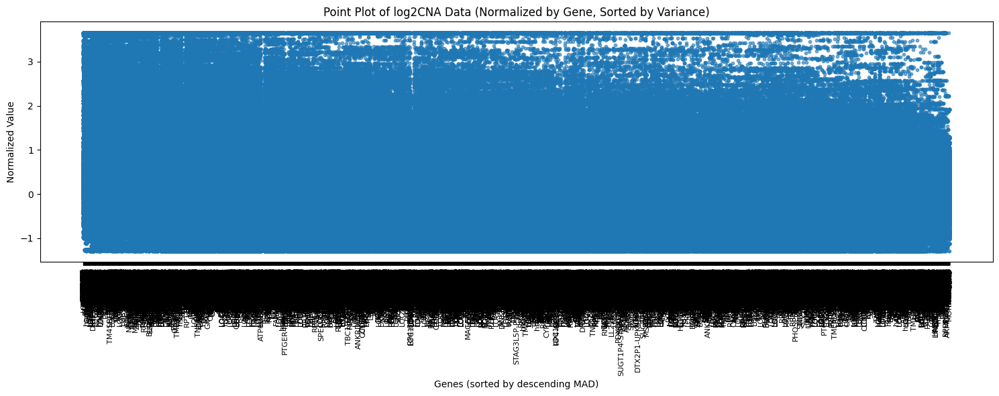

In [12]:

def custom_variance(data):
    """
    Computes variance for each gene (row) by:
    1. Subtracting each value from the mean.
    2. Squaring the differences.
    3. Taking the mean of the squared differences.
    """
    # Compute the mean for each gene
    mean_values = data.mean(axis=1)

    # Compute squared deviations from the mean
    squared_deviations = (data.sub(mean_values, axis=0)) ** 2

    # Compute variance as the mean of squared deviations (without dividing by n-1)
    variance_custom = squared_deviations.mean(axis=1)
    
    return variance_custom


def preprocess(data):
    """
    Preprocesses the data by:
    1. Calculating the Mean Absolute Deviation (MAD) for each gene.
    2. Sorting genes in descending order based on MAD.
    3. Reordering the data based on the sorted genes.
    4. Applying Z-score normalization to each gene.
    
    Returns:
    - Normalized DataFrame with genes ordered by MAD.
    """

    # Compute Mean Absolute Deviation (MAD) for each gene (row)
    mean_values = data.mean(axis=1)
    absolute_deviation = (data.sub(mean_values, axis=0)).abs()
    mad_values = absolute_deviation.mean(axis=1)

    # Sort genes by MAD in descending order
    sorted_genes = mad_values.sort_values(ascending=False).index

    # Reorder the data based on sorted MAD values
    data_sorted = data.loc[sorted_genes]

    return data_sorted


def plot_normalized_data(data, title):
    """
    Plots normalized data with:
    - X-axis: Genes (sorted by MAD)
    - Y-axis: Normalized values (Z-scores)
    - Each dot represents a single sample value for a gene.
    """

    # Reset index to bring gene names into the first column
    data = data.reset_index()

    # Rename the first column (assuming it holds gene names)
    gene_col_name = data.columns[0]  # First column should be gene names
    data = data.rename(columns={gene_col_name: 'Gene'})  # Explicitly name it 'Gene'

    # Convert DataFrame to long format for plotting
    long_df = data.melt(id_vars='Gene', var_name='Sample', value_name='Normalized Value')

    # Create a mapping to assign each gene a numeric x-coordinate (based on the sorted order)
    gene_order = {gene: i for i, gene in enumerate(data['Gene'])}
    long_df['Gene_order'] = long_df['Gene'].map(gene_order)

    # Plot
    plt.figure(figsize=(15, 6))
    plt.scatter(long_df['Gene_order'], long_df['Normalized Value'], alpha=0.6, s=10)

    # Format x-axis
    plt.xticks(ticks=list(gene_order.values()), labels=list(gene_order.keys()), rotation=90, fontsize=8)
    plt.xlabel("Genes (sorted by descending MAD)")
    plt.ylabel("Normalized Value")
    plt.title(title)
    plt.tight_layout()
    plt.show()




# Assuming mrna_numeric and cna_numeric are your preprocessed DataFrames 
# (with genes as rows and samples as columns).

# Plot for mRNA data
plot_normalized_data(preprocess(mrna_numeric), "Point Plot of mRNA Seq Data (Normalized by Gene, Sorted by Variance)")

# Plot for log2CNA data
plot_normalized_data(preprocess(cna_numeric), "Point Plot of log2CNA Data (Normalized by Gene, Sorted by Variance)")


## 14. Survival Threshold Split Analysis

The final analysis checks different survival-month thresholds to identify which threshold creates the most balanced classification split. For each threshold, the code compares the number of patients who died before the threshold against the number of patients who survived at least to that threshold.

The bar height shows the absolute difference between the two groups. A lower bar means a better-ratioed split because the two classes are closer in size. Therefore, the threshold with the lowest value is the best candidate for creating a balanced binary survival label for model training.

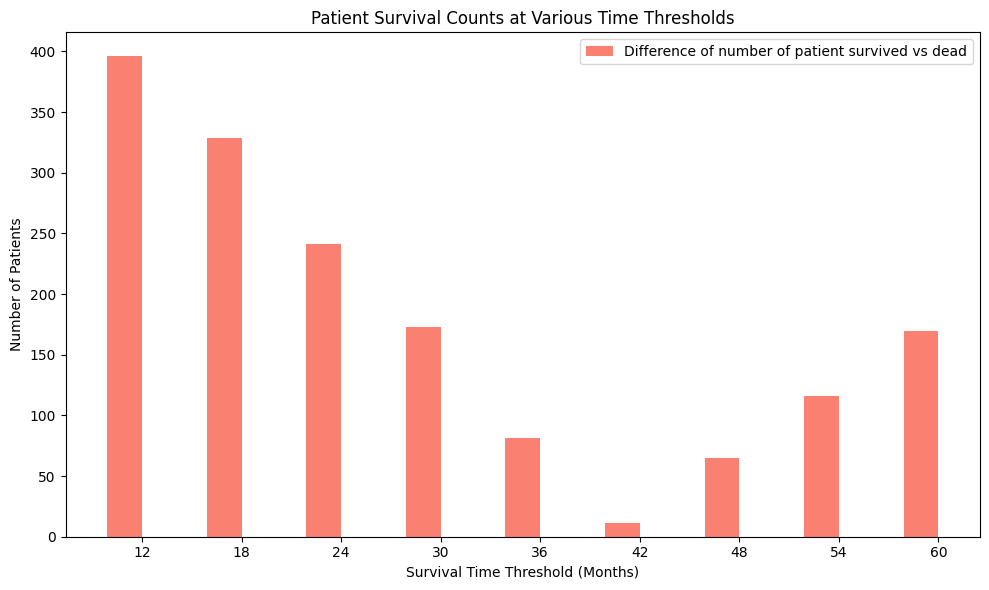

In [13]:

# File path for the patient data Excel file
file_path = "../Datafile Raw/patient data.xlsx"

# Load the data into a DataFrame (assuming data is in the first sheet)
df = pd.read_excel(file_path)

# Define thresholds from 12 to 60 months at 6-month intervals
thresholds = list(range(12, 61, 6))  # [12, 18, 24, 30, 36, 42, 48, 54, 60]

# Lists to hold counts for each threshold
ratio_count = []

ratio_count
# Loop through each threshold and count patients based on survival time and status
for t in thresholds:
    # Count patients with status "Deceased" whose survival time is less than the threshold
    deceased_count = df[(df["Overall Survival Status"] == "1:DECEASED") & 
                        (df["Months of disease-specific survival"] < t)].shape[0]
    # Count all patients (regardless of status) whose survival time is greater than or equal to the threshold
    survived_count = df[df["Months of disease-specific survival"] >= t].shape[0]
    ratio_count.append(abs(deceased_count-survived_count))

# Prepare the x-axis positions for each threshold
x = np.arange(len(thresholds))
bar_width = 0.35

# Create the plot
plt.figure(figsize=(10, 6))
plt.bar(x - bar_width/2, ratio_count, width=bar_width, color='salmon', label='Difference of number of patient survived vs dead')


plt.xlabel('Survival Time Threshold (Months)')
plt.ylabel('Number of Patients')
plt.title('Patient Survival Counts at Various Time Thresholds')
plt.xticks(x, thresholds)
plt.legend()
plt.tight_layout()
plt.show()


### Threshold Interpretation

This plot supports the choice of survival threshold for the classification task. The lowest bar indicates the most balanced split between short-survival and longer-survival patients. A more balanced split is useful because it reduces the chance that the classifier learns mainly from class imbalance rather than meaningful omics patterns.

In this analysis, the 42-month threshold produced the best class balance, so it was selected as the target cutoff for the final model. This threshold was chosen for modeling practicality and class-distribution balance; it should not be interpreted as a clinical or medical standard for ovarian cancer survival.